In [1]:
import os
import sys

project_root = os.path.abspath("..")   # if the notebook is inside notebooks/
sys.path.insert(0, project_root)
print(project_root)

c:\Projects\Service Event Framework\Improvement\code


In [2]:
import os
import numpy as np
import pandas as pd
from utils.dbconnection import engine
from pathlib import Path
from utils.config import config

2026-10-13 12:02:43,583 - Logger: Log file: c:\Projects\Service Event Framework\Improvement\code\logs\SEF_Improvement_20261013_120243.log
2026-10-13 12:02:43,607 - SQLAlchemy: Database connection configured successfully!


# Service Event Governance & Intelligence Framework

This notebook demonstrates techniques for identifying:
- Misspellings
- Duplicate Service Events
- Naming inconsistencies
- Parent-child hierarchies
- Material mapping issues
- Unclassified materials
- AI-driven Service Event recommendations
- Governance scoring

In [3]:
# Install Dependencies
# pip install pandas rapidfuzz sentence-transformers scikit-learn networkx

In [4]:
# Sample Service Events

# events = [
#     'Battery Replacement',
#     'Batery Replacement',
#     'Blade Replacement',
#     'Blade Replacment',
#     'Replace Blade',
#     'Blade Repair'
# ]

xlsx_path = os.path.join(config.locations.outputs, "service_event_analysis.xlsx")
df = pd.read_excel(xlsx_path, sheet_name="event_material")
df.columns

Index(['DServiceEventID', 'Serviceeventcode', 'ServiceEventName', 'AND_OR',
       'Priority', 'confidence', 'Itemnumber', 'MaterialName', 'MaterialGroup',
       'MaterialGroupDescription'],
      dtype='str')

In [5]:
events = df['ServiceEventName'].unique()

## 1. Misspelling Detection using RapidFuzz

In [6]:
import pandas as pd
from rapidfuzz import fuzz

results = []

for i in range(len(events)):
    for j in range(i+1, len(events)):
        score = fuzz.ratio(events[i], events[j])

        if score > 90:
            results.append({
                'event1': events[i],
                'event2': events[j],
                'score': score
            })

pd.DataFrame(results)

,event1,event2,score
0,Gear Oil Lubrication Motor Replace,Gear Oil Lubrication Motor VFD Replace,94.444444
1,CCI Circuit Breaker Replacement,LPC Circuit Breaker Replacement,93.548387
2,CCI Circuit Breaker Replacement,PPR Circuit Breaker Replacement,90.322581
3,CCI Circuit Breaker Replacement,NAC Circuit Breaker Replacement,93.548387
4,LPC Circuit Breaker Replacement,PPR Circuit Breaker Replacement,93.548387
5,LPC Circuit Breaker Replacement,NAC Circuit Breaker Replacement,93.548387
6,PPR Circuit Breaker Replacement,NAC Circuit Breaker Replacement,90.322581
7,BB Grease Consumption,MBA Grease Consumption,93.023256
8,NLE Battery Replacement,TLF Battery Replacement,91.304348
9,NLE CT Module Replacement,TLF CT Module Replacement,92.000000


In [7]:
len(results)

18

## 2. Sentence Transformer Embeddings

In [8]:
events = np.array(events)

In [9]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer('all-mpnet-base-v2')

embeddings = model.encode(events)

print(embeddings.shape)

c:\Users\SRVID\.conda\envs\build_app\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 929.91it/s]


(486, 768)


## 3. Semantic Similarity Matrix

In [10]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix = cosine_similarity(embeddings)

similarity_df = pd.DataFrame(
    similarity_matrix,
    columns=events,
    index=events
).round(3)
similarity_df = similarity_df.sort_values(by=events[0], ascending=False).reset_index()
similarity_df.rename(columns={'index': 'Serviceevent'}, inplace=True)
similarity_df.head()

,Serviceevent,Blade Bearing Replacement,Generator Bearing Replacement,Main Bearing Arrangement Replacement,Pitch Cylinder Replacement,Proportional Valve Replacement,Yaw Gear Replacement,GearBox IMS Stage,GearBox HSS Stage,GearBox Planetary Stage,...,Gear Oil Hose Replace,Hyd Oil Hose Replace,SMT Erosion Repair,Powertrain Speed Sensor Replace,CAC O-Ring Replace,Hub Light Element Replace,Nacelle Floor Base Plate Nut Assy,CubePower Arc Vent Assy,BB Grease Collection Can Assy,Nacelle Controller EKEY Securing KIT
0,Blade Bearing Replacement,1.000,0.791,0.725,0.519,0.300,0.416,0.027,0.135,0.097,...,0.292,0.311,0.182,0.154,0.379,0.446,0.334,0.079,0.096,0.161
1,Blade Bearing Seal Replace,0.868,0.673,0.585,0.437,0.284,0.318,0.031,0.103,0.074,...,0.347,0.391,0.222,0.161,0.446,0.394,0.337,0.097,0.064,0.260
2,Generator Bearing Replacement,0.791,1.000,0.752,0.509,0.325,0.416,0.032,0.125,0.145,...,0.327,0.300,0.145,0.237,0.332,0.413,0.359,0.151,0.176,0.171
3,Main Bearing Arrangement Replacement,0.725,0.752,1.000,0.494,0.352,0.440,0.063,0.176,0.138,...,0.272,0.286,0.091,0.219,0.369,0.459,0.348,0.135,0.149,0.163
4,Internal Hoist Bearing replace,0.684,0.669,0.697,0.453,0.249,0.427,0.066,0.159,0.100,...,0.268,0.317,0.113,0.229,0.366,0.438,0.360,0.066,0.057,0.162


In [11]:
# similarity_df_melt = similarity_df.melt(id_vars='Serviceevent', var_name='Serviceevent_2', value_name='Similarity')
# similarity_df_melt = similarity_df_melt[similarity_df_melt['Serviceevent'] != similarity_df_melt['Serviceevent_2']]
# similarity_df_melt['Similarity'] = np.round(similarity_df_melt['Similarity'],2)
# similarity_df_melt = similarity_df_melt.loc[(similarity_df_melt['Similarity']!=1)]
# similarity_df_melt = similarity_df_melt.sort_values(by='Similarity', ascending=False).reset_index(drop=True)
# similarity_df_melt.head()

## 4. Duplicate Event Detection

In [12]:
duplicates=[]

for i in range(len(events)):
    for j in range(i+1,len(events)):

        score=similarity_matrix[i][j]

        if score > 0.50:
            duplicates.append({
                'event1':events[i],
                'event2':events[j],
                'similarity':score
            })

similarity_df_melt = pd.DataFrame(duplicates).sort_values(by='similarity', ascending=False)
similarity_df_melt['similarity'] = np.round(similarity_df_melt['similarity'],2)
similarity_df_melt.head()

,event1,event2,similarity
2494,Gear Oil Motor VFD Replace,Gear Oil Lubrication Motor VFD Replace,0.94
3148,Blade Bearing Torque Arm Assembly,Blade Bearing Torque Arm,0.92
1569,PPR AC CAP Replacement,PPR DC CAP Replacement,0.92
2477,GBX ODM Pump Motor Replace,GBX ODM Pump Replace,0.92
2894,Service Lift Wire fix bracket Steel,Service Lift Wire fix bracket,0.92


In [13]:
np.round(similarity_df_melt['similarity'],1).value_counts()

similarity
0.6    1565
0.5    1087
0.7     424
0.8     132
0.9      31
Name: count, dtype: int64

In [14]:
similarity_df_melt.loc[similarity_df_melt['similarity'] == 0.60]

,event1,event2,similarity
3072,NLE Surge Protector Replace,NLE EMC Filter Replace,0.6
1686,Pitch Hyd Cable Replacement,Down Conductor Cable Replace,0.6
2188,Hyd Oil Level Sensor Replace,MBA Oil Inlet Temperature Sensor,0.6
2740,Tower Flange HV Bolt Replace,Tower Support brace Replace,0.6
1027,CCI Relay Replacement,APS Relay Replace,0.6
...,...,...,...
716,NLE CT Mod Counter Replace,NLE CT Module Replacement,0.6
1550,Hyd cool Pipe Replacement,Hyd Unit Yaw System Replace,0.6
3011,Tower Ladder Rubber End,Tower Ladder Rung Fitting,0.6
796,SCADA Cable Replacement,SCADA Power Meter Replace,0.6


## 5. Service Event Clustering

In [15]:
from sklearn.cluster import AgglomerativeClustering

cluster_model = AgglomerativeClustering(
    n_clusters=100,
    metric='l2',
    linkage='ward'
)

labels = cluster_model.fit_predict(embeddings)

agg_clust_df = pd.DataFrame({
    'event':events,
    'cluster':labels
}).sort_values('cluster')

agg_clust_df.head(10)

,event,cluster
425,Tower Platform Bushing Mat,0
426,Gear Drain PFTT Bushing Mat,0
193,MSC Stack Mat Replace,0
192,LSC Stack Mat Replace,0
357,FSS Fire Detection Tube Replace,1
358,Fire Suppression System Replace,1
191,FSS Safety Cylinder,1
262,FSS Pressure Switch Replace,1
355,Fire Extinguisher Replace,1
166,ShadowDetectKit Consumption,2


In [16]:
clust_cnt = pd.DataFrame(agg_clust_df['cluster'].value_counts()).reset_index()
m1 = agg_clust_df.merge(clust_cnt, on='cluster', how='inner')
m1.head()

,event,cluster,count
0,Tower Platform Bushing Mat,0,4
1,Gear Drain PFTT Bushing Mat,0,4
2,MSC Stack Mat Replace,0,4
3,LSC Stack Mat Replace,0,4
4,FSS Fire Detection Tube Replace,1,5


In [41]:
clust_cnt.head()

,cluster,count
0,5,17
1,16,15
2,4,11
3,8,10
4,23,10


In [42]:
m15 = m1.loc[m1['cluster']==16]
m15_sorted = m15.sort_values(by='event', key=lambda col: col.str[::-1])
m15_sorted

,event,cluster,count
105,Yaw Worm Gear TL Replace,16,15
96,Yaw Brg Pad Replace,16,15
93,YAW Sensor Module Replace,16,15
101,Yaw Spring Pack Replace,16,15
94,Yaw Grease Wheel Replace,16,15
102,Yaw Motor Fan Replace,16,15
97,YAW Circuit Breaker Replace,16,15
99,Yaw Torque Limiter Replace,16,15
92,Yaw Module Vibration Sensor Replace,16,15
95,Yaw Grease Tray Replace,16,15


## 6. Naming Convention Validation

In [43]:
import re

df = pd.DataFrame({
    'event_name':[
        'Blade Replacement',
        'Replacement - Blade',
        'Battery Inspection',
        'replace battery'
    ]
})

pattern=r'^[A-Za-z\s]+ (Replacement|Repair|Inspection|Maintenance)$'

df['valid_name']=df['event_name'].apply(
    lambda x: bool(re.match(pattern,x))
)

df

,event_name,valid_name
0,Blade Replacement,True
1,Replacement - Blade,False
2,Battery Inspection,True
3,replace battery,False


## 7. Ambiguous Event Detection

In [44]:
generic_keywords=[
    'Issue',
    'Problem',
    'Failure',
    'Inspection',
    'Repair'
]

def ambiguous(name):
    if len(name.split()) <= 2:
        return True

    if name.strip() in generic_keywords:
        return True

    return False

df = pd.DataFrame({'event_name':events})
df['ambiguous']=df['event_name'].apply(ambiguous)
df.loc[df['ambiguous']==True]

,event_name,ambiguous
82,CAC Blower,True
83,CAC ClimateModule,True
84,Convertor Module,True
87,Generator GreasePump,True
92,Tower Accesories,True
114,PIAHydrValve Replacement,True
120,Cable Replacement,True
150,BusbarEquipment Replace,True
153,HubPilzSafetyIO Replace,True
154,NonNAFTAsprayConsumption,True


## 8. Parent-Child Hierarchy Discovery

In [45]:
events_hierarchy=[
    'Blade Repair',
    'Blade Structural Repair',
    'Blade Surface Repair',
    'Blade Leading Edge Repair'
]

relationships=[]

for parent in events_hierarchy:
    for child in events_hierarchy:
        if parent != child and parent in child:
            relationships.append((parent,child))

pd.DataFrame(
    relationships,
    columns=['Parent','Child']
)

,Parent,Child


## 9. Material Overlap Analysis

In [46]:
criterion_df=pd.DataFrame({
    'service_event':['Blade Repair','Blade Repair','Blade Replacement','Blade Replacement'],
    'material_no':[1001,1002,1002,1003]
})

event_materials=(
    criterion_df.groupby('service_event')['material_no']
    .apply(set)
)

results=[]

for e1 in event_materials.index:
    for e2 in event_materials.index:

        if e1 >= e2:
            continue

        intersection=len(
            event_materials[e1].intersection(event_materials[e2])
        )

        union=len(
            event_materials[e1].union(event_materials[e2])
        )

        jaccard=intersection/union

        results.append({
            'event1':e1,
            'event2':e2,
            'material_overlap':jaccard
        })

pd.DataFrame(results)

,event1,event2,material_overlap
0,Blade Repair,Blade Replacement,0.333333


## 10. Unclassified Material Detection

In [47]:
material_master=pd.DataFrame({
    'material_no':[1001,1002,1003,1004,1005]
})

criterion_materials=set(
    criterion_df['material_no']
)

all_materials=set(
    material_master['material_no']
)

missing_materials=all_materials-criterion_materials

missing_materials

{1004, 1005}

## 11. AI Recommendation for Unmapped Materials

In [48]:
import numpy as np

service_events=[
    'Blade Replacement',
    'Battery Replacement',
    'Generator Repair'
]

material_descriptions=[
    'Blade stud assembly kit',
    'Battery backup module'
]

material_embeddings=model.encode(material_descriptions)
event_embeddings=model.encode(service_events)

sim=cosine_similarity(
    material_embeddings,
    event_embeddings
)

recommendations=[]

for i,material in enumerate(material_descriptions):

    best=np.argmax(sim[i])

    recommendations.append({
        'material':material,
        'recommended_event':service_events[best],
        'confidence':float(sim[i][best])
    })

pd.DataFrame(recommendations)

,material,recommended_event,confidence
0,Blade stud assembly kit,Blade Replacement,0.477705
1,Battery backup module,Battery Replacement,0.417339


## 12. Service Event Governance Agent Prompt

In [49]:
event_list=[
    'Blade Replace',
    'Blade Replacement',
    'Battery Replacement'
]

prompt=f'''
Review the following Service Event names.

Identify:
1. Duplicate events
2. Misspellings
3. Naming inconsistencies
4. Retirement candidates
5. Parent-child hierarchies

Events:
{event_list}

Return JSON output.
'''

print(prompt)


Review the following Service Event names.

Identify:
1. Duplicate events
2. Misspellings
3. Naming inconsistencies
4. Retirement candidates
5. Parent-child hierarchies

Events:
['Blade Replace', 'Blade Replacement', 'Battery Replacement']

Return JSON output.



## 13. Composite Governance Score

In [50]:
scores=pd.DataFrame({
    'SemanticSimilarity':[0.90],
    'MaterialOverlap':[0.80],
    'ServiceOrderOverlap':[0.70],
    'CostExposure':[0.60]
})

scores['FinalScore']=(
    0.4*scores['SemanticSimilarity']+
    0.3*scores['MaterialOverlap']+
    0.2*scores['ServiceOrderOverlap']+
    0.1*scores['CostExposure']
)

scores

,SemanticSimilarity,MaterialOverlap,ServiceOrderOverlap,CostExposure,FinalScore
0,0.9,0.8,0.7,0.6,0.8


## 14. Network Graph of Potential Duplicate Events

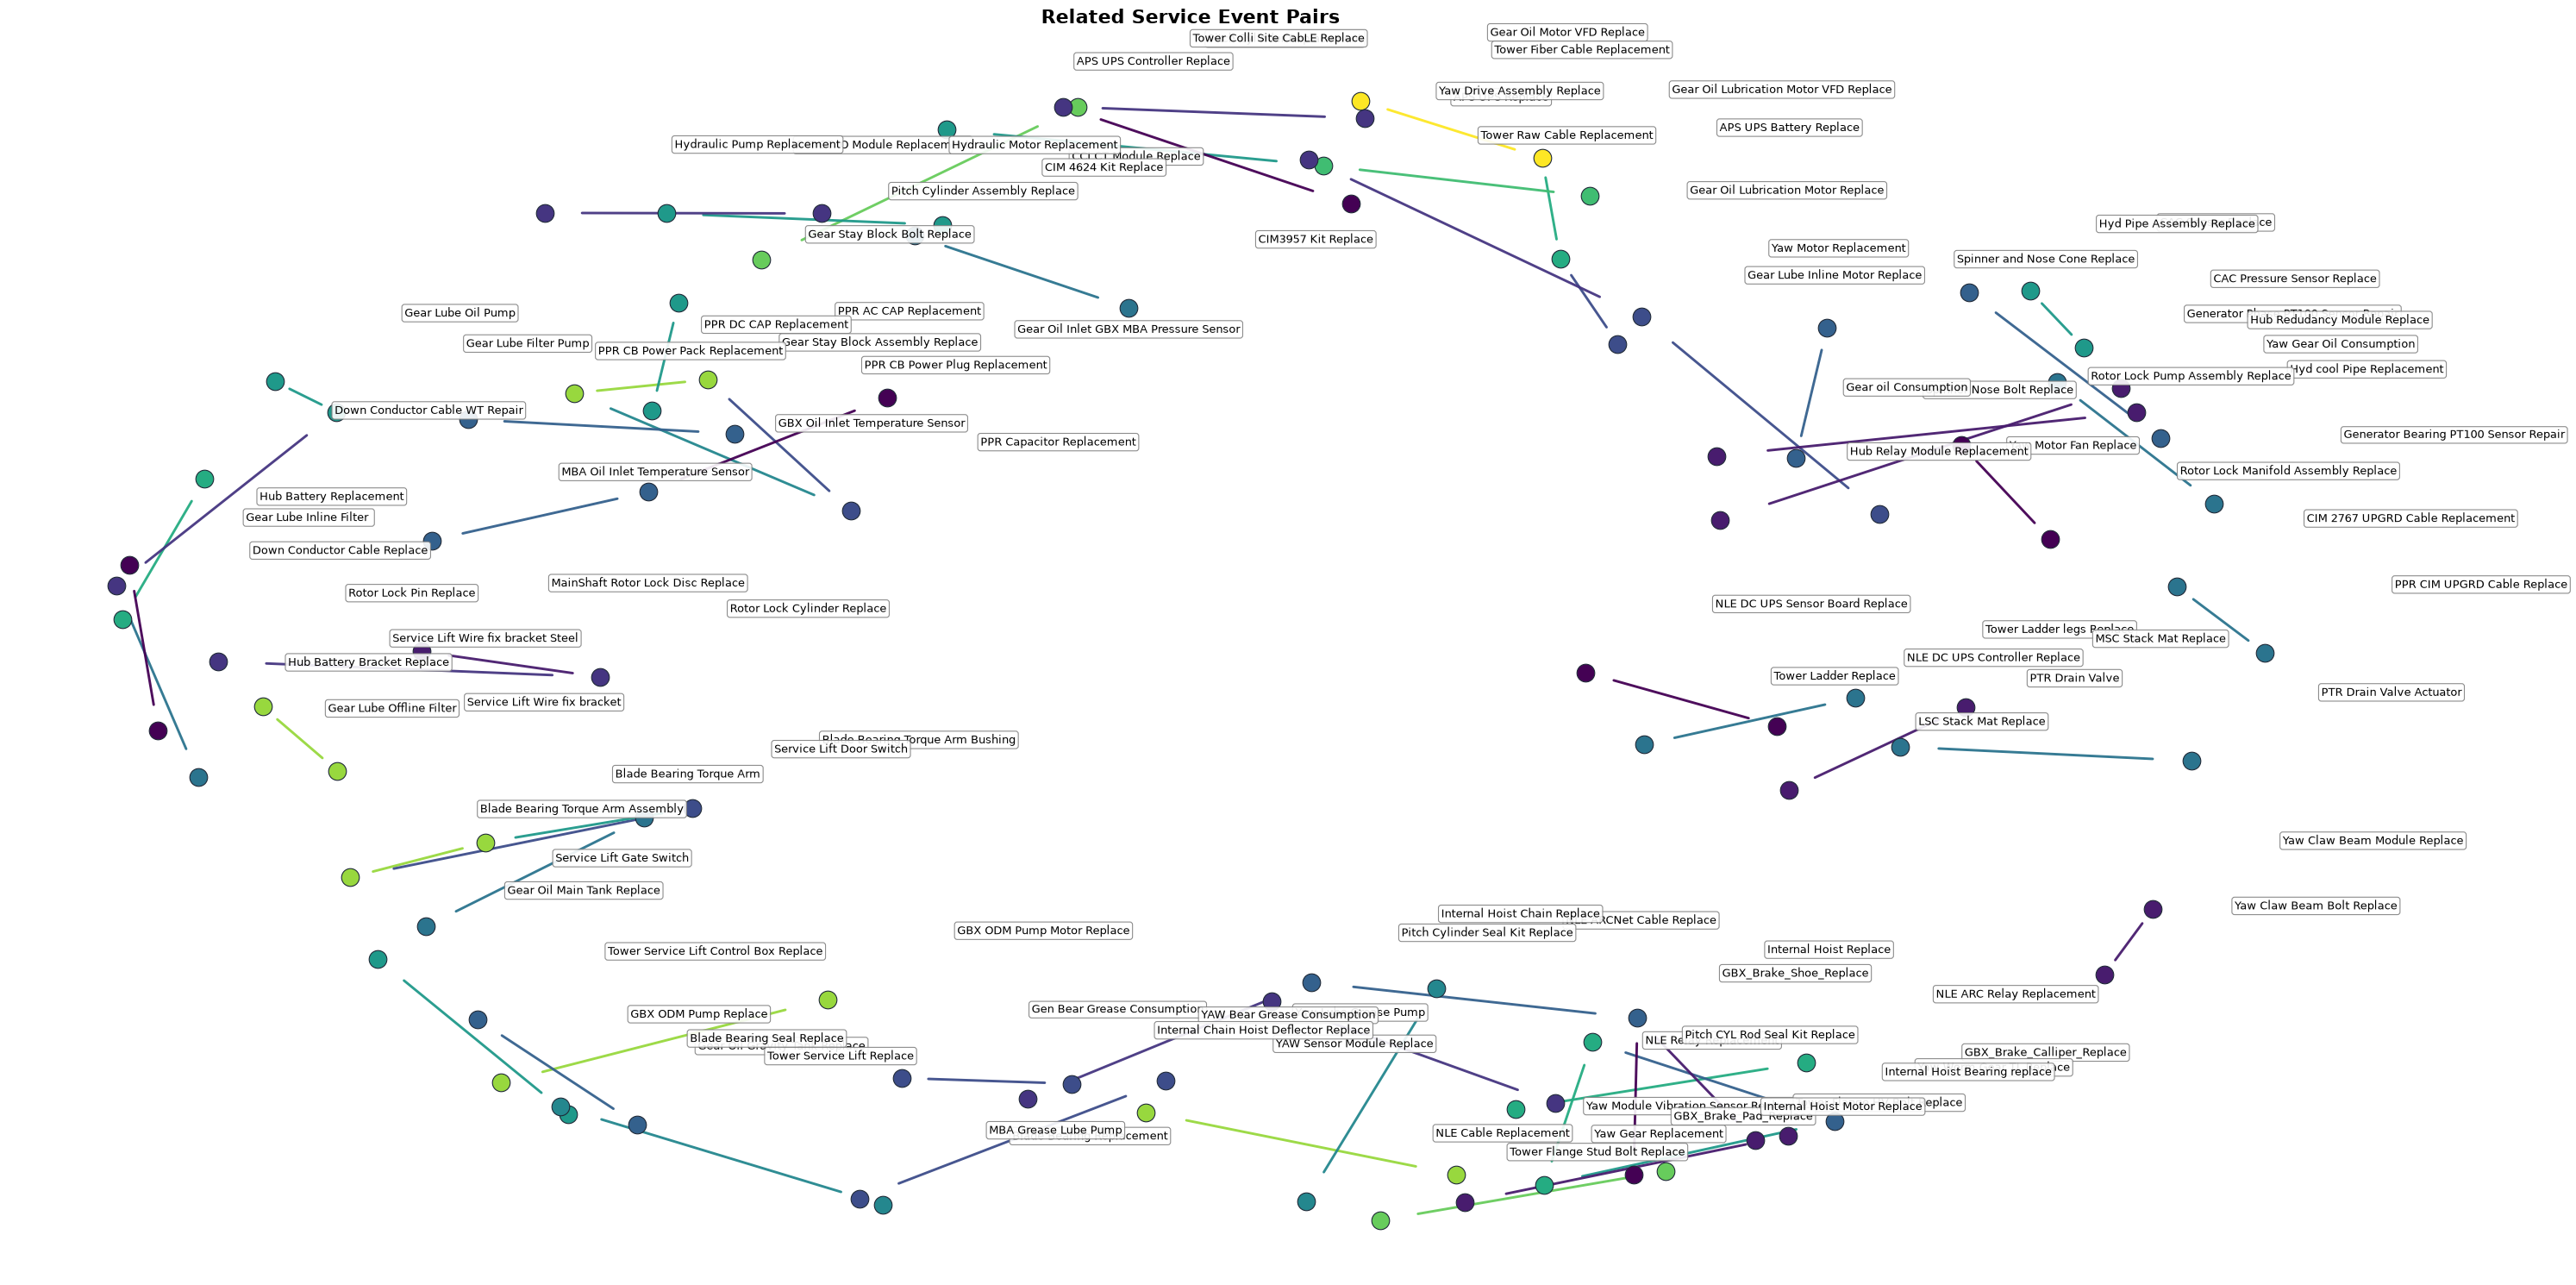

In [66]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

G = nx.Graph()

topdup = similarity_df_melt.loc[similarity_df_melt['similarity'] > 0.8].copy()

for _, row in topdup.iterrows():
    e1 = str(row['event1'])
    e2 = str(row['event2'])
    sim = float(row['similarity'])
    G.add_edge(e1, e2, weight=sim)

if G.number_of_edges() == 0:
    print('No duplicate pairs above threshold.')
else:
    pos = nx.spring_layout(G, seed=42, k=1.8, iterations=300)
    edge_list = list(G.edges())
    edge_weights = [G[u][v]['weight'] for u, v in edge_list]

    if edge_weights:
        min_w = min(edge_weights)
        max_w = max(edge_weights)
        try:
            cmap = plt.get_cmap('viridis')
        except AttributeError:
            cmap = plt.cm.get_cmap('viridis')
        norm = Normalize(vmin=min_w, vmax=max_w)
        edge_colors = [cmap(norm(w)) for w in edge_weights]
    else:
        edge_colors = ['#3b82f6'] * len(edge_list)

    fig, ax = plt.subplots(figsize=(30, 15))

    # Draw edges between related service events with short, mostly horizontal connectors.
    for idx, (u, v) in enumerate(edge_list):
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        dx = x2 - x1
        dy = y2 - y1

        # Shorten the segment to leave space around each node.
        shorten = 0.10
        x1s, y1s = x1 + dx * shorten, y1 + dy * shorten
        x2s, y2s = x2 - dx * shorten, y2 - dy * shorten

        edge_color = edge_colors[idx]

        ax.annotate(
            '',
            xy=(x2s, y2s),
            xytext=(x1s, y1s),
            arrowprops=dict(
                arrowstyle='-',
                lw=2.1,
                color=edge_color,
                alpha=0.95,
                shrinkA=8,
                shrinkB=8,
                connectionstyle='arc3,rad=0.0'
            ),
            zorder=1
        )

    # Color each event node based on its pair while keeping all edges in a darker constant color.
    node_color_map = {}
    for idx, (u, v) in enumerate(edge_list):
        node_color_map.setdefault(u, edge_colors[idx])
        node_color_map.setdefault(v, edge_colors[idx])

    for node, (x, y) in pos.items():
        label_offset_x = 0.12
        label_offset_y = 0.12
        dot_color = node_color_map.get(node, '#3b82f6')

        ax.scatter(
            [x],
            [y],
            s=220,
            color=dot_color,
            edgecolors='#1f2937',
            linewidths=0.8,
            zorder=4
        )

        ax.text(
            x + label_offset_x,
            y + label_offset_y,
            node,
            fontsize=9,
            ha='left',
            va='center',
            bbox=dict(
                boxstyle='round,pad=0.25',
                facecolor='white',
                edgecolor='gray',
                linewidth=0.8,
                alpha=0.9,
            ),
            zorder=6
        )

    ax.set_title('Related Service Event Pairs', fontsize=16, weight='bold', pad=18)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

## 15. Misspelt Service Events

In [38]:
import re
import pandas as pd
import enchant

# Check all service events in the clustering dataframe, not just a subset.
all_events = (
    agg_clust_df['event']
    .dropna()
    .astype(str)
    .unique()
)

d = enchant.Dict("en_US")

# Domain-specific words that are valid even if they are not in the general English dictionary.
excluded_words = {
    'busbar',
    'trafo',
    'scada',
    'ddau',
    'adaptor',
    # Add more here as needed
}


def english_word_tokens(name):
    tokens = [
        t for t in re.sub(r'[^a-zA-Z\s]', ' ', name.lower()).split()
        if t and len(t) > 1
    ]
    return [t for t in tokens if not re.fullmatch(r'[a-z]{1,3}', t)]

rows = []
for event in sorted(set(all_events)):
    bad_words = []
    for word in english_word_tokens(event):
        word = word.lower()

        # ignore domain-specific terms or uppercase abbreviations
        if word in excluded_words:
            continue
        if re.fullmatch(r'[A-Z]{2,}', word.upper()) and word.isupper():
            continue
        if not d.check(word):
            bad_words.append(word)

    rows.append({
        'event': event,
        'misspelled_words': bad_words,
        'review_required': bool(bad_words)
    })

topic_15_spellcheck = pd.DataFrame(rows)
topic_15_spellcheck = topic_15_spellcheck.sort_values('review_required', ascending=False)

In [39]:
topic_15_spellcheck['review_required'].value_counts()

review_required
False    417
True      69
Name: count, dtype: int64

In [41]:
topic_15_spellcheck.loc[topic_15_spellcheck['review_required']].head(20)

,event,misspelled_words,review_required
149,Gear Oil Pump Motor Assy,[assy],True
307,PPR SKiiPack Replacement,[skiipack],True
339,Program Logix Controller CPU Replace,[logix],True
66,CMS Accelation Sensor Replace,[accelation],True
304,PPR HYBRD Cable Replace,[hybrd],True
303,PPR HVCable Replacement,[hvcable],True
63,CIM 2767 UPGRD Cable Replacement,[upgrd],True
213,Hydraulic Pump Motor Assy,[assy],True
388,Thysitor Assy Replace,"[thysitor, assy]",True
170,Generator GreasePump,[greasepump],True


In [42]:
df_save_dict = {
    'Event Clustering': similarity_df_melt,
    'Spell Check': topic_15_spellcheck
}



from pathlib import Path

output_dir = Path(config.locations.outputs)
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "service_event_inconsistencies.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    for sheet_name, df_sheet in df_save_dict.items():
        if isinstance(df_sheet, pd.DataFrame):
            df_sheet.to_excel(writer, sheet_name=sheet_name, index=False)
        else:
            pd.DataFrame(df_sheet).to_excel(writer, sheet_name=sheet_name, index=False)

excel_path

WindowsPath('C:/Projects/Service Event Framework/Improvement/code/data/outputs/service_event_inconsistencies.xlsx')